# Système d'Intelligence Artificielle pour l'évaluation du risque de crédit

**Objectif :** construire un modèle de Machine Learning capable de prédire, au moment de l'octroi d'un crédit, si ce crédit risque de tomber en **retard de remboursement de plus de 30 jours** (crédit « à risque »).

**Démarche suivie :**
1. Chargement des données
2. Exploration des données (EDA)
3. Définition de la variable cible
4. Nettoyage et préparation des données
5. Sélection des variables (et gestion de la fuite de données)
6. Séparation apprentissage / test
7. Entraînement et comparaison de plusieurs modèles
8. Optimisation du meilleur modèle
9. Évaluation finale et choix du seuil de décision
10. Interprétation (importance des variables)
11. Mise en place du système : sauvegarde du modèle et prédiction pour un nouveau client
12. Conclusion

## 1. Importation des librairies et chargement des données

In [1]:
import warnings
warnings.filterwarnings('ignore')

import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import joblib

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

Sur **Google Colab**, la cellule ci-dessous demande de téléverser le fichier `DataSet_Credit.xlsx` (en local, le fichier est lu directement).

In [2]:
import os
FICHIER = 'DataSet_Credit.xlsx'
if not os.path.exists(FICHIER):
    from google.colab import files
    files.upload()   # choisir DataSet_Credit.xlsx

df_brut = pd.read_excel(FICHIER)
print('Dimensions :', df_brut.shape)
# Aperçu sans les identifiants (numéros de crédit et de membre)
df_brut.drop(columns=['NUMERO_CREDIT', 'NUMERO_MEMBRE']).head()

Dimensions : (15189, 12)


,AGENCE,SECTEUR ACTIVITE,TYPE DE CREDIT,ANNEE OUVERTURE,MOIS OUVERTURE,Age,Nombre de Crédit antérieur,SOLDE_CREDIT,MONTANT_DEBOURSE,RETARD
0,MECYD,CONSOMMATION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,2023,4,52,6.0,303237.93,700000,0 JOUR
1,MECYD,CONSTRUCTION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,2023,4,52,6.0,563155.88,1300000,0 JOUR
2,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,995330.03,2000000,0 JOUR
3,MECYD,CONSOMMATION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,205577.41,450000,0 JOUR
4,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,123473.53,500000,0 JOUR


## 2. Exploration des données (EDA)

In [3]:
df_brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 15189 entries, 0 to 15188
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   NUMERO_CREDIT               15189 non-null  int64  
 1   AGENCE                      15189 non-null  str    
 2   SECTEUR ACTIVITE            15189 non-null  str    
 3   TYPE DE CREDIT              15189 non-null  str    
 4   NUMERO_MEMBRE               15189 non-null  int64  
 5   ANNEE OUVERTURE             15189 non-null  int64  
 6   MOIS OUVERTURE              15189 non-null  int64  
 7   Age                         15189 non-null  int64  
 8   Nombre de Crédit antérieur  13179 non-null  float64
 9   SOLDE_CREDIT                15189 non-null  float64
 10  MONTANT_DEBOURSE            15189 non-null  int64  
 11  RETARD                      15188 non-null  str    
dtypes: float64(2), int64(6), str(4)
memory usage: 1.4 MB


In [4]:
# Valeurs manquantes par colonne
df_brut.isna().sum()

NUMERO_CREDIT                    0
AGENCE                           0
SECTEUR ACTIVITE                 0
TYPE DE CREDIT                   0
NUMERO_MEMBRE                    0
ANNEE OUVERTURE                  0
MOIS OUVERTURE                   0
Age                              0
Nombre de Crédit antérieur    2010
SOLDE_CREDIT                     0
MONTANT_DEBOURSE                 0
RETARD                           1
dtype: int64

In [5]:
df_brut.describe().T

,count,mean,std,min,25%,50%,75%,max
NUMERO_CREDIT,15189.0,8.380176e+04,8.292804e+04,15708.00,30964.00,42892.0,46825.0,237648.0
NUMERO_MEMBRE,15189.0,2.137708e+07,5.021151e+07,1.00,11955.00,17557.0,21599.0,200006200.0
ANNEE OUVERTURE,15189.0,2.025186e+03,1.682917e+00,2017.00,2025.00,2026.0,2026.0,2026.0
MOIS OUVERTURE,15189.0,5.639739e+00,3.259502e+00,1.00,3.00,5.0,8.0,12.0
Age,15189.0,4.506011e+01,8.512567e+00,2.00,45.00,50.0,50.0,53.0
Nombre de Crédit antérieur,13179.0,3.708324e+00,1.290450e+00,1.00,2.00,4.0,5.0,7.0
SOLDE_CREDIT,15189.0,7.696178e+05,3.094233e+06,0.01,138379.51,250000.0,545645.2,221319622.1
MONTANT_DEBOURSE,15189.0,1.089963e+06,4.607067e+06,50000.00,200000.00,400000.0,900000.0,340000000.0


On renomme les colonnes avec des noms courts, sans accents ni espaces, pour faciliter le travail.

In [6]:
df = df_brut.copy()
df.columns = ['NUMERO_CREDIT', 'AGENCE', 'SECTEUR', 'TYPE_CREDIT', 'NUMERO_MEMBRE',
              'ANNEE_OUVERTURE', 'MOIS_OUVERTURE', 'AGE', 'NB_CREDITS_ANT',
              'SOLDE_CREDIT', 'MONTANT_DEBOURSE', 'RETARD']
df.drop(columns=['NUMERO_CREDIT', 'NUMERO_MEMBRE']).head()

,AGENCE,SECTEUR,TYPE_CREDIT,ANNEE_OUVERTURE,MOIS_OUVERTURE,AGE,NB_CREDITS_ANT,SOLDE_CREDIT,MONTANT_DEBOURSE,RETARD
0,MECYD,CONSOMMATION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,2023,4,52,6.0,303237.93,700000,0 JOUR
1,MECYD,CONSTRUCTION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,2023,4,52,6.0,563155.88,1300000,0 JOUR
2,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,995330.03,2000000,0 JOUR
3,MECYD,CONSOMMATION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,205577.41,450000,0 JOUR
4,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,2023,5,52,6.0,123473.53,500000,0 JOUR


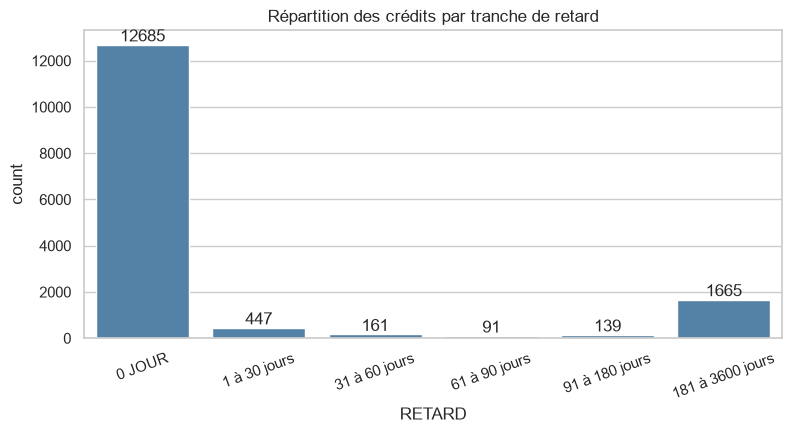

In [7]:
# Distribution des retards
ordre = ['0 JOUR', '1 à 30 jours', '31 à 60 jours', '61 à 90 jours', '91 à 180 jours', '181 à 3600 jours']
plt.figure(figsize=(9, 4))
ax = sns.countplot(data=df, x='RETARD', order=ordre, color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Répartition des crédits par tranche de retard')
plt.xticks(rotation=20)
plt.show()

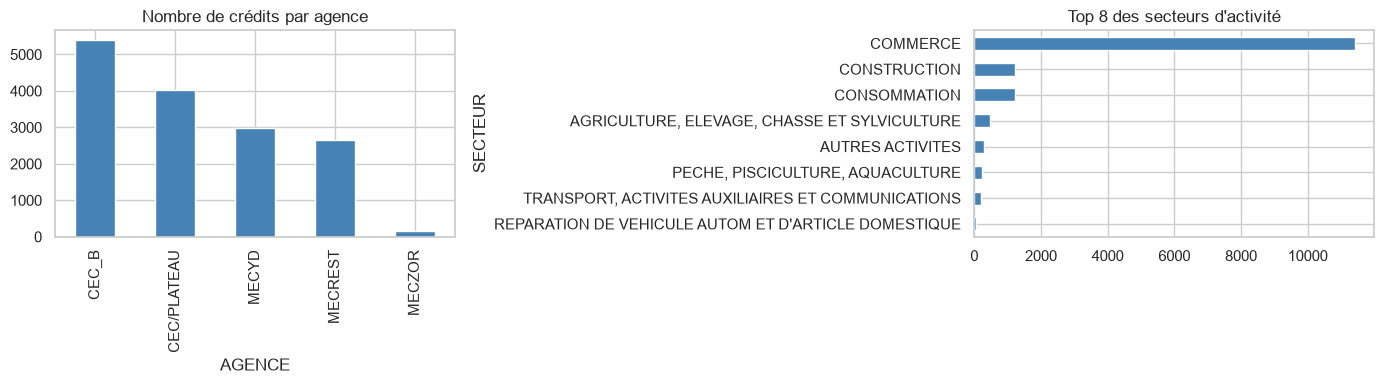

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['AGENCE'].value_counts().plot.bar(ax=axes[0], color='steelblue', title='Nombre de crédits par agence')
df['SECTEUR'].value_counts().head(8).plot.barh(ax=axes[1], color='steelblue', title="Top 8 des secteurs d'activité")
axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

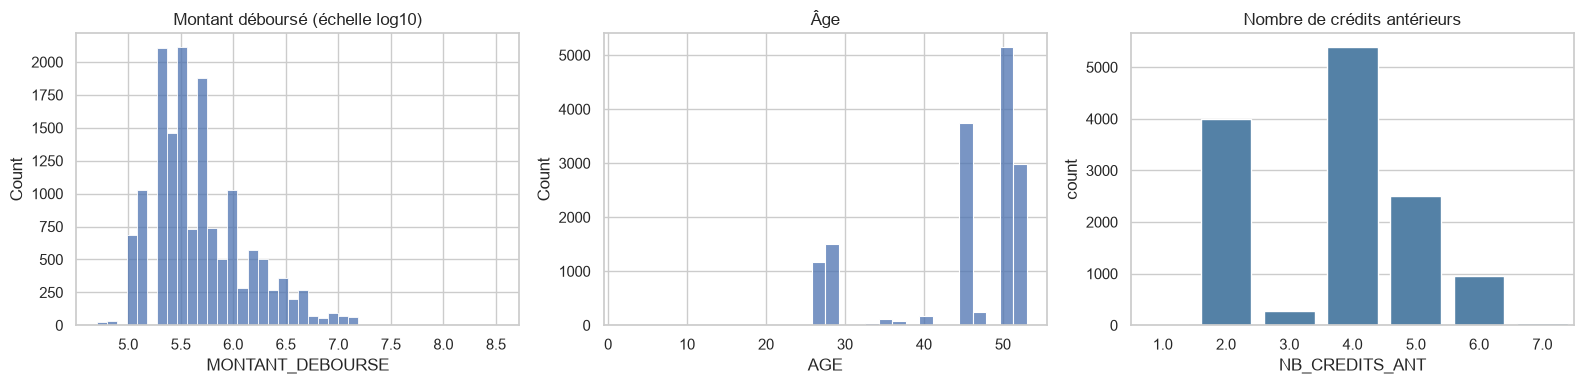

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(np.log10(df['MONTANT_DEBOURSE']), bins=40, ax=axes[0])
axes[0].set_title('Montant déboursé (échelle log10)')
sns.histplot(df['AGE'], bins=30, ax=axes[1]); axes[1].set_title('Âge')
sns.countplot(x=df['NB_CREDITS_ANT'], ax=axes[2], color='steelblue'); axes[2].set_title('Nombre de crédits antérieurs')
plt.tight_layout(); plt.show()

**Observations :**
- 15 189 crédits et 12 colonnes.
- La variable `RETARD` est la variable à prédire ; une seule ligne n'a pas de valeur.
- `NB_CREDITS_ANT` contient 2 010 valeurs manquantes, toutes dans l'agence MECYD.
- `AGE` contient une valeur aberrante (2 ans).
- `MONTANT_DEBOURSE` est très asymétrique (de 50 000 à 340 000 000 FCFA), d'où l'usage du logarithme.
- `TYPE_CREDIT` compte 92 libellés différents, avec des différences d'accents ou de majuscules pour un même produit.

## 3. Définition de la variable cible

`RETARD` contient 6 tranches. On la transforme en variable **binaire** `RISQUE` :
- **0 = bon crédit** : 0 jour de retard ou retard de 1 à 30 jours (retard léger, souvent technique)
- **1 = crédit à risque** : retard de **plus de 30 jours**

Ce seuil correspond au **PAR 30** (*Portefeuille à Risque à 30 jours*), l'indicateur de référence en microfinance (notamment dans l'espace UEMOA/BCEAO).

In [10]:
df = df.dropna(subset=['RETARD'])          # suppression de la ligne sans cible
df['RISQUE'] = (~df['RETARD'].isin(['0 JOUR', '1 à 30 jours'])).astype(int)

print(df['RISQUE'].value_counts())
print(f"\nTaux de crédits à risque : {df['RISQUE'].mean():.1%}")

RISQUE
0    13132
1     2056
Name: count, dtype: int64

Taux de crédits à risque : 13.5%


Les classes sont **déséquilibrées** (environ 13,5 % de crédits à risque). Il faudra en tenir compte :
- stratification lors du découpage train/test,
- pondération des classes (`class_weight='balanced'`),
- choix de métriques adaptées (AUC, rappel, F1) plutôt que la seule *accuracy*.

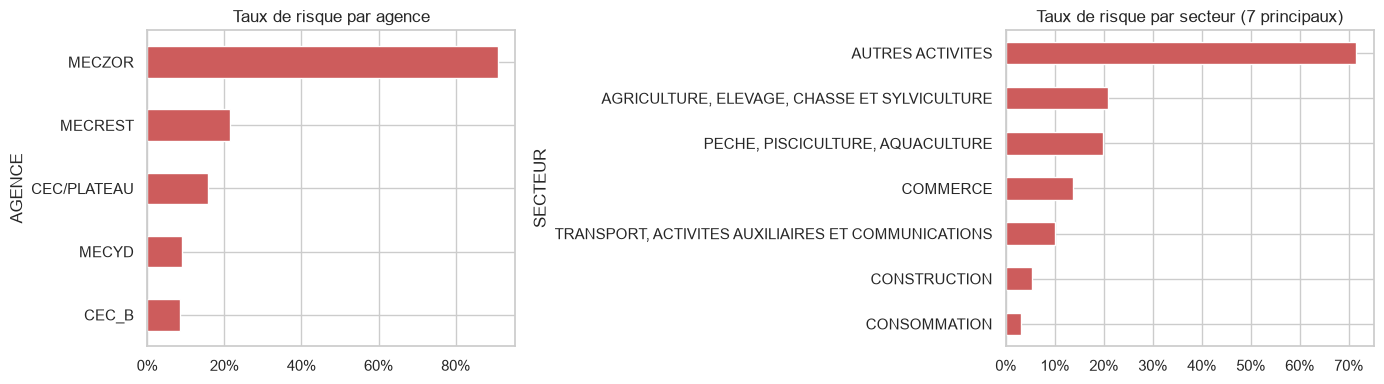

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby('AGENCE')['RISQUE'].mean().sort_values().plot.barh(ax=axes[0], color='indianred')
axes[0].set_title('Taux de risque par agence'); axes[0].xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
top_sect = df['SECTEUR'].value_counts().head(7).index
df[df['SECTEUR'].isin(top_sect)].groupby('SECTEUR')['RISQUE'].mean().sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Taux de risque par secteur (7 principaux)'); axes[1].xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
plt.tight_layout(); plt.show()

## 4. Nettoyage et préparation des données

### 4.1 Doublons

In [12]:
print('Lignes dupliquées :', df.duplicated().sum())
print('Doublons (agence, numéro de crédit) :', df.duplicated(['AGENCE', 'NUMERO_CREDIT']).sum())

Lignes dupliquées : 0
Doublons (agence, numéro de crédit) : 0


Il n'y a aucun doublon : un numéro de crédit est unique **au sein d'une agence**.

### 4.2 Harmonisation du type de crédit
On supprime les accents, on met en majuscules et on retire les espaces en trop, puis on extrait deux nouvelles variables plus générales :
- `DUREE` : court terme (6-12 mois), moyen terme (1-2 ans ou 2-3 ans), long terme (3-10 ans)
- `FAMILLE` : entente PAM/DER (crédits en partenariat avec l'État), trésorerie, personnel, consommation, commercial, habitat...

In [13]:
def normaliser(texte):
    texte = unicodedata.normalize('NFKD', str(texte)).encode('ascii', 'ignore').decode().upper()
    return re.sub(r'\s+', ' ', texte).strip()

df['TYPE_CREDIT'] = df['TYPE_CREDIT'].map(normaliser)
print('Nombre de types de crédit après normalisation :', df['TYPE_CREDIT'].nunique())

def duree(t):
    if re.search(r'\bLT\b|3 ANS A 10', t): return 'LT 3-10 ans'
    if '2 ANS A 3' in t:                    return 'MT 2-3 ans'
    if '1 AN' in t:                         return 'MT 1-2 ans'
    return 'CT 6-12 mois'

def famille(t):
    for mot, nom in [('ENTENTE', 'ENTENTE PAM/DER'), ('TRESO', 'TRESORERIE'), ('PERSONNEL', 'PERSONNEL'), ('CONSOMMATION', 'CONSOMMATION'),
                     ('COMMERCIAL', 'COMMERCIAL'), ('HABITAT', 'HABITAT'), ('EQUIPEMENT', 'EQUIPEMENT')]:
        if mot in t: return nom
    return 'AUTRE'

df['DUREE'] = df['TYPE_CREDIT'].map(duree)
df['FAMILLE'] = df['TYPE_CREDIT'].map(famille)
pd.crosstab(df['FAMILLE'], df['DUREE'])

Nombre de types de crédit après normalisation : 91


DUREE,CT 6-12 mois,LT 3-10 ans,MT 1-2 ans,MT 2-3 ans
FAMILLE,,,,
AUTRE,35,44,231,66
COMMERCIAL,12,6,397,41
CONSOMMATION,509,0,0,0
ENTENTE PAM/DER,326,31,771,56
EQUIPEMENT,8,11,0,0
HABITAT,0,206,20,54
PERSONNEL,166,478,640,342
TRESORERIE,10738,0,0,0


### 4.3 Valeurs aberrantes et manquantes
- Un âge inférieur à 18 ans est impossible pour un emprunteur : il est remplacé par une valeur manquante.
- Les valeurs manquantes (`AGE`, `NB_CREDITS_ANT`) seront remplacées par la **médiane**, à l'intérieur du pipeline (calculée uniquement sur les données d'apprentissage pour éviter toute fuite).
- On crée `LOG_MONTANT = log(montant)` pour réduire l'asymétrie.
- Les catégories très rares (moins de 20 crédits) seront regroupées automatiquement par l'encodeur.

In [14]:
print('Âges < 18 :', (df['AGE'] < 18).sum())
df.loc[df['AGE'] < 18, 'AGE'] = np.nan
df['LOG_MONTANT'] = np.log(df['MONTANT_DEBOURSE'])
df[['AGE', 'NB_CREDITS_ANT', 'LOG_MONTANT']].isna().sum()

Âges < 18 : 1


AGE                  1
NB_CREDITS_ANT    2010
LOG_MONTANT          0
dtype: int64

## 5. Sélection des variables et fuite de données

Le modèle doit évaluer le risque **au moment de la demande de crédit**. On ne peut donc utiliser que les informations connues à ce moment-là.

| Variable | Utilisée | Raison |
|---|---|---|
| AGENCE, SECTEUR, TYPE_CREDIT, DUREE, FAMILLE | Oui | connues à la demande |
| AGE, NB_CREDITS_ANT, LOG_MONTANT, MOIS_OUVERTURE | Oui | connues à la demande |
| NUMERO_CREDIT, NUMERO_MEMBRE | Non | identifiants, sans valeur prédictive |
| SOLDE_CREDIT | **Non** | connu seulement *après* l'octroi : il reflète déjà le remboursement (fuite de données) |
| ANNEE_OUVERTURE | **Non** | un crédit ancien encore présent dans le portefeuille est presque toujours un crédit en défaut (ex. 2019 : 100 % en retard) : fuite de données |

Avec `SOLDE_CREDIT` et `ANNEE_OUVERTURE`, on obtiendrait un score artificiellement proche de la perfection, inutilisable en pratique pour un nouveau client. Le tableau ci-dessous le montre :

In [15]:
print(pd.crosstab(df['ANNEE_OUVERTURE'], df['RISQUE'], normalize='index').round(2))

RISQUE              0     1
ANNEE_OUVERTURE            
2017             0.00  1.00
2018             0.33  0.67
2019             0.00  1.00
2020             0.38  0.62
2021             0.34  0.66
2022             0.29  0.71
2023             0.73  0.27
2024             0.46  0.54
2025             0.83  0.17
2026             0.99  0.01


In [16]:
VARS_NUM = ['AGE', 'NB_CREDITS_ANT', 'LOG_MONTANT', 'MOIS_OUVERTURE']
VARS_CAT = ['AGENCE', 'SECTEUR', 'TYPE_CREDIT', 'DUREE', 'FAMILLE']

X = df[VARS_NUM + VARS_CAT]
y = df['RISQUE']
X.head()

,AGE,NB_CREDITS_ANT,LOG_MONTANT,MOIS_OUVERTURE,AGENCE,SECTEUR,TYPE_CREDIT,DUREE,FAMILLE
0,52.0,6.0,13.458836,4,MECYD,CONSOMMATION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,LT 3-10 ans,AUTRE
1,52.0,6.0,14.077875,4,MECYD,CONSTRUCTION,CREDITS AFSSEF A LT DE + 3 ANS A 10 ANS AU +,LT 3-10 ans,AUTRE
2,52.0,6.0,14.508658,5,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,LT 3-10 ans,PERSONNEL
3,52.0,6.0,13.017003,5,MECYD,CONSOMMATION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,LT 3-10 ans,PERSONNEL
4,52.0,6.0,13.122363,5,MECYD,CONSTRUCTION,CREDITS PERSONNEL A LT DE + 3 ANS A 10 ANS AU +,LT 3-10 ans,PERSONNEL


## 6. Séparation des données en apprentissage (80 %) et test (20 %)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train :', X_train.shape, f'- taux de risque {y_train.mean():.1%}')
print('Test  :', X_test.shape,  f'- taux de risque {y_test.mean():.1%}')

Train :

 (12150, 9) - taux de risque 13.5%
Test  : (3038, 9) - taux de risque 13.5%


### Pipeline de prétraitement
- Variables numériques : imputation par la médiane puis standardisation.
- Variables catégorielles : encodage *One-Hot* ; les catégories rares (< 20 occurrences) sont regroupées.

In [18]:
preprocesseur = ColumnTransformer([
    ('num', Pipeline([('imputation', SimpleImputer(strategy='median')),
                      ('standardisation', StandardScaler())]), VARS_NUM),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20), VARS_CAT),
])

## 7. Entraînement et comparaison de plusieurs modèles

On compare 5 algorithmes de classification avec une **validation croisée à 5 plis** sur les données d'apprentissage. La métrique principale est l'**AUC ROC**, adaptée aux classes déséquilibrées.

In [19]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

modeles = {
    'Régression logistique': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Arbre de décision':     DecisionTreeClassifier(max_depth=8, min_samples_leaf=10,
                                                    class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest':         RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced',
                                                    n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting':     GradientBoostingClassifier(random_state=RANDOM_STATE),
    'XGBoost':               XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                                           colsample_bytree=0.8, scale_pos_weight=ratio,
                                           eval_metric='logloss', random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for nom, modele in modeles.items():
    pipe = Pipeline([('prep', preprocesseur), ('modele', modele)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f'{nom:25s} AUC = {scores.mean():.4f} (± {scores.std():.4f})')

Régression logistique     AUC = 0.8760 (± 0.0067)


Arbre de décision         AUC = 0.8695 (± 0.0131)


Random Forest             AUC = 0.8937 (± 0.0070)


Gradient Boosting         AUC = 0.8955 (± 0.0017)


XGBoost                   AUC = 0.8905 (± 0.0079)


### Évaluation sur le jeu de test

In [20]:
lignes, probas = [], {}
for nom, modele in modeles.items():
    pipe = Pipeline([('prep', preprocesseur), ('modele', modele)]).fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[nom] = p
    lignes.append({'Modèle': nom,
                   'AUC': roc_auc_score(y_test, p),
                   'Accuracy': accuracy_score(y_test, pred),
                   'Précision': precision_score(y_test, pred),
                   'Rappel': recall_score(y_test, pred),
                   'F1': f1_score(y_test, pred)})

comparaison = pd.DataFrame(lignes).set_index('Modèle').sort_values('AUC', ascending=False)
comparaison.round(3)

,AUC,Accuracy,Précision,Rappel,F1
Modèle,,,,,
Random Forest,0.924,0.908,0.627,0.791,0.700
XGBoost,0.923,0.907,0.624,0.791,0.697
Gradient Boosting,0.923,0.943,0.958,0.608,0.744
Régression logistique,0.912,0.865,0.501,0.783,0.611
Arbre de décision,0.909,0.887,0.561,0.769,0.649


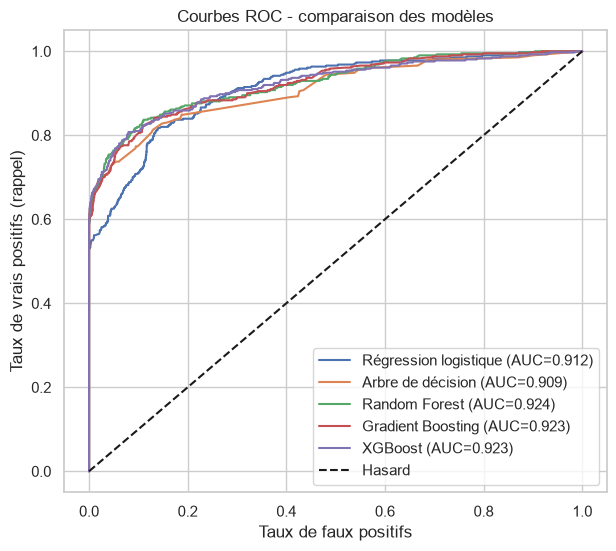

In [21]:
plt.figure(figsize=(7, 6))
for nom, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{nom} (AUC={roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Hasard')
plt.xlabel('Taux de faux positifs'); plt.ylabel('Taux de vrais positifs (rappel)')
plt.title('Courbes ROC - comparaison des modèles'); plt.legend(); plt.show()

**Remarque :** le Gradient Boosting de scikit-learn n'utilise pas de pondération des classes ; avec le seuil de 0,5, il détecte donc moins de crédits à risque (rappel plus faible), même si son AUC reste correct. L'AUC permet de comparer les modèles indépendamment du seuil.

## 8. Optimisation des hyperparamètres

On optimise le **Random Forest** (parmi les meilleurs AUC, robuste et facile à interpréter) avec une recherche par grille (`GridSearchCV`).

In [22]:
pipe_rf = Pipeline([('prep', preprocesseur),
                    ('modele', RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))])
grille = {
    'modele__n_estimators':     [200],
    'modele__max_depth':        [None, 20],
    'modele__min_samples_leaf': [1, 3],
    'modele__max_features':     ['sqrt', 0.3],
}
# 8 combinaisons x 3 plis = 24 entraînements (quelques minutes sur Colab)
recherche = GridSearchCV(pipe_rf, grille, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                         scoring='roc_auc', n_jobs=-1, verbose=1)
recherche.fit(X_train, y_train)
print('Meilleurs paramètres :', recherche.best_params_)
print(f'AUC en validation croisée : {recherche.best_score_:.4f}')
modele_final = recherche.best_estimator_

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Meilleurs paramètres : {'modele__max_depth': None, 'modele__max_features': 'sqrt', 'modele__min_samples_leaf': 3, 'modele__n_estimators': 200}
AUC en validation croisée : 0.8905


## 9. Évaluation finale et choix du seuil de décision

In [23]:
p_test = modele_final.predict_proba(X_test)[:, 1]
print(f'AUC sur le test : {roc_auc_score(y_test, p_test):.4f}')

AUC sur le test : 0.9243


Par défaut, un crédit est classé « à risque » si sa probabilité dépasse 0,5. Pour une institution de crédit, **ne pas détecter un mauvais payeur** (faux négatif) coûte généralement plus cher que refuser un bon client (faux positif). On choisit donc le seuil qui maximise le F1-score, un compromis entre précision et rappel.

*Remarque : idéalement, ce seuil se choisit sur un jeu de validation séparé ; on utilise ici le jeu de test pour rester simple.*

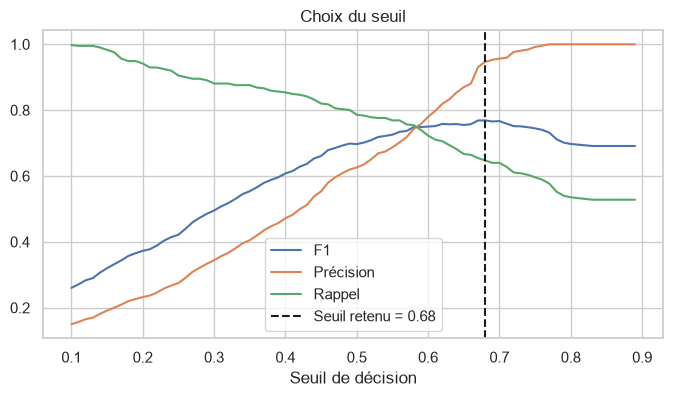

In [24]:
seuils = np.arange(0.1, 0.9, 0.01)
f1s = [f1_score(y_test, (p_test >= s).astype(int)) for s in seuils]
SEUIL = float(seuils[int(np.argmax(f1s))])

plt.figure(figsize=(8, 4))
plt.plot(seuils, f1s, label='F1')
plt.plot(seuils, [precision_score(y_test, (p_test >= s).astype(int), zero_division=0) for s in seuils], label='Précision')
plt.plot(seuils, [recall_score(y_test, (p_test >= s).astype(int)) for s in seuils], label='Rappel')
plt.axvline(SEUIL, color='k', ls='--', label=f'Seuil retenu = {SEUIL:.2f}')
plt.xlabel('Seuil de décision'); plt.legend(); plt.title('Choix du seuil'); plt.show()

                 precision    recall  f1-score   support

     Bon crédit       0.95      0.99      0.97      2627
Crédit à risque       0.95      0.65      0.77       411

       accuracy                           0.95      3038
      macro avg       0.95      0.82      0.87      3038
   weighted avg       0.95      0.95      0.94      3038



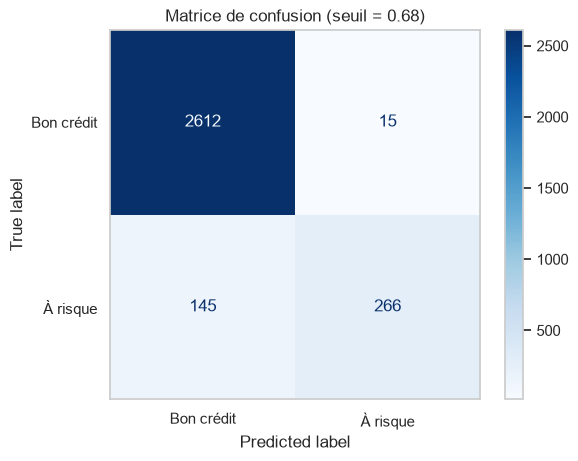

In [25]:
pred_final = (p_test >= SEUIL).astype(int)
print(classification_report(y_test, pred_final, target_names=['Bon crédit', 'Crédit à risque']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final),
                       display_labels=['Bon crédit', 'À risque']).plot(cmap='Blues')
plt.title(f'Matrice de confusion (seuil = {SEUIL:.2f})'); plt.grid(False); plt.show()

## 10. Interprétation : importance des variables

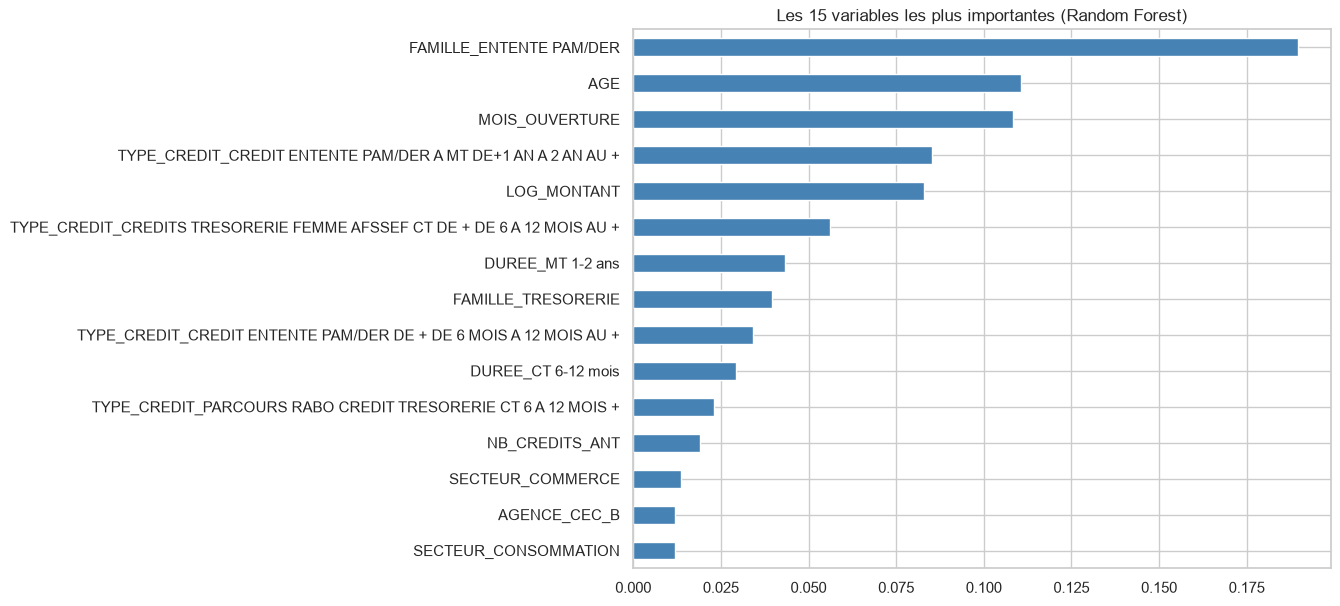

In [26]:
noms = modele_final.named_steps['prep'].get_feature_names_out()
importances = pd.Series(modele_final.named_steps['modele'].feature_importances_, index=noms)
importances.index = importances.index.str.replace('num__', '').str.replace('cat__', '')

plt.figure(figsize=(9, 7))
importances.sort_values().tail(15).plot.barh(color='steelblue')
plt.title('Les 15 variables les plus importantes (Random Forest)'); plt.show()

**Interprétation :**
- Le **type de crédit** est le facteur le plus déterminant. Les crédits **« entente PAM/DER »** (financements en partenariat avec l'État) sont presque tous en retard de plus de 30 jours dans ce portefeuille : il s'agit d'un produit à très haut risque.
- Viennent ensuite le **mois d'ouverture** (les crédits accordés en février et septembre sont plus souvent en retard, ce qui peut s'expliquer par des effets saisonniers comme la soudure ou les fêtes), l'**âge** de l'emprunteur et le **montant** du crédit.
- Les crédits de **trésorerie de court terme** (AFSSEF, micro-entrepreneurs) sont les moins risqués.
- Le **nombre de crédits antérieurs** et l'**agence** jouent un rôle plus faible.

## 11. Mise en place du système d'IA

On sauvegarde le pipeline complet (prétraitement + modèle) et le seuil, puis on crée une fonction qui évalue le risque d'une nouvelle demande de crédit.

In [27]:
joblib.dump({'pipeline': modele_final, 'seuil': SEUIL}, 'modele_risque_credit.joblib')
print('Modèle sauvegardé dans modele_risque_credit.joblib')

Modèle sauvegardé dans modele_risque_credit.joblib


In [28]:
systeme = joblib.load('modele_risque_credit.joblib')

def evaluer_credit(agence, secteur, type_credit, age, nb_credits_anterieurs, montant, mois_ouverture):
    t = normaliser(type_credit)
    demande = pd.DataFrame([{
        'AGE': age, 'NB_CREDITS_ANT': nb_credits_anterieurs, 'LOG_MONTANT': np.log(montant),
        'MOIS_OUVERTURE': mois_ouverture, 'AGENCE': agence, 'SECTEUR': secteur,
        'TYPE_CREDIT': t, 'DUREE': duree(t), 'FAMILLE': famille(t)}])
    proba = systeme['pipeline'].predict_proba(demande)[0, 1]
    if proba >= systeme['seuil']:
        decision = 'CRÉDIT À RISQUE : étude approfondie / garanties supplémentaires'
    else:
        decision = 'RISQUE FAIBLE : avis favorable'
    print(f'Probabilité de retard > 30 jours : {proba:.1%}  ->  {decision}')
    return proba

# Exemple 1
evaluer_credit(agence='CEC_B', secteur='COMMERCE',
               type_credit='CRÉDITS TRESORERIE FEMME AFSSEF  CT DE + DE 6 À 12 MOIS AU +',
               age=50, nb_credits_anterieurs=4, montant=300000, mois_ouverture=3)

# Exemple 2
evaluer_credit(agence='CEC/PLATEAU', secteur='COMMERCE',
               type_credit='Crédit entente PAM/DER A MT DE+1 AN A 2 AN AU +',
               age=29, nb_credits_anterieurs=2, montant=1000000, mois_ouverture=2)

Probabilité de retard > 30 jours : 14.3%  ->  RISQUE FAIBLE : avis favorable
Probabilité de retard > 30 jours : 90.5%  ->  CRÉDIT À RISQUE : étude approfondie / garanties supplémentaires


np.float64(0.9051919829676704)

## 12. Conclusion

- Nous avons construit un système d'IA qui estime la probabilité qu'un crédit tombe en **retard de plus de 30 jours (PAR 30)**, à partir des seules informations disponibles au moment de la demande.
- Après nettoyage (harmonisation des libellés, valeur aberrante, valeurs manquantes) et création de variables (`DUREE`, `FAMILLE`, `LOG_MONTANT`), 5 modèles ont été comparés. Les méthodes d'ensemble (**Random Forest**, **XGBoost**, **Gradient Boosting**) donnent les meilleurs résultats, avec un AUC d'environ **0,92** sur le jeu de test. Le Random Forest optimisé a été retenu.
- Les variables `SOLDE_CREDIT` et `ANNEE_OUVERTURE` ont été volontairement exclues : elles provoquent une **fuite de données** et donneraient des performances trompeuses.
- Le seuil de décision a été ajusté pour obtenir le meilleur compromis entre crédits à risque détectés (rappel) et fausses alertes (précision).

**Limites et pistes d'amélioration :**
- Les données ne contiennent pas d'informations financières sur l'emprunteur (revenus, garanties, historique de remboursement détaillé) ; les ajouter améliorerait le modèle.
- Une grande partie du pouvoir prédictif vient du type de produit (notamment PAM/DER) : le modèle est moins précis pour distinguer les clients au sein d'un même produit.
- Il faudrait vérifier la stabilité du modèle dans le temps (entraîner sur les anciens crédits, tester sur les plus récents).
- Le modèle pourrait être déployé dans une petite application (Streamlit, Gradio) à destination des agents de crédit.